## Финальный проект

#### *«Я чувствую себя как функция арктангенса, которая приближается к асимптоте.» — Теория большого взрыва*

Это финальный проект продуктового блока курса «Продуктовые метрики». За него можно получить максимум 60 баллов.

**Дедлайны**   
Жесткий дедлайн: 25.10.2026 23:59 по МСК.

После жесткого дедлайна работы не принимаются.

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание аннулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например final_project). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/final_project_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import requests

from statsmodels.tsa.seasonal import STL
from scipy.stats import norm
from scipy.stats import t
import math

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

### Case Study. Улучшение сервиса доставки из ресторанов 🌮

**Легенда**   
Вы присоединились к продуктовой команде сервиса доставки из ресторанов в роли аналитика. Близится планирование следующего квартала, пора готовить бэклог инициатив. Продакт-менеджер особенно беспокоится об удовлетворенности пользователей — за последний месяц выросло число отмен и жалоб на задержки.

Вам поставлена задача: провести исследование текущих значений метрик, выдвинуть гипотезу о проблеме и предложить её решение.

In [3]:
df = pd.read_csv('data/final_project_delivery.csv')

df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,travel_time_min,delivery_distance_km,promotion_used,platform,city_region,user_id,user_segment
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,5.0,3.48,no,Android,Belem,5737.0,returning
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.00,0.77,13.0,9.0,15.9,5.0,1.29,no,iOS,Parque das Nacoes,4095.0,new
2,343,2022-11-01 21:07:01,2022-11-01 21:40:07,delivered,NaN,29.90,3.53,44.0,10.6,15.4,15.1,5.88,no,iOS,Parque das Nacoes,15991.0,returning
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,13.9,3.36,no,Android,Alfama,1773.0,returning
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,35.1,5.80,no,iOS,Baixa,5203.0,returning


Описание данных:

- order_id — уникальный идентификатор заказа
- order_time — timestamp создания заказа
- delivery_time – timestamp доставки заказа
- status — статус заказа, принимает 2 значения: delivered и cancelled
- cancellation_reason — причина отмены заказа: Cancelled by user (отменена пользователем) и No courier available (нет доступных курьеров)
- order_value — стоимость заказа
- delivery_fee — стоимость доставки
- estimated_delivery_time_min — прогнозное время доставки
- time_to_assign_courier_min — время до назначения курьера
- actual_preparation_time_min — время приготовления заказа рестораном
- travel_time_min — суммарное время на дорогу курьера до ресторана и до конечного пользователя
- delivery_distance_km — расстояние от адреса доставки до адреса ресторана
- promotion_used — был ли заказ совершен с использованием промокода или акции
- platform — платформа, с которой совершен заказ
- city_region — район города, в который планируется доставка
- user_id — уникальный идентификатор пользователя, сделавшего заказ
- user_segment — сегмент пользователя (новый или вернувшийся)    

### Часть 1. Исследование

#### 1. Динамика основных метрик — 3 балла
Рассчитайте и визуализируйте по дням:
- Число заказов, число доставленных заказов (статус delivered);
- Completion Rate (Доставленные заказы / Все заказы), Cancellation Rate (Отмененные заказы / Все заказы);
- Среднее и медианное время доставки в минутах (рассчитывается как разница между delivery_time и order_time), средний чек заказа, среднюю стоимость доставки.

Сделайте выводы:
- Есть ли выраженный тренд?
- Может быть какие-то дни кажутся подозрительными на предмет аномалий?

In [8]:
df['order_time'] = pd.to_datetime(df['order_time'])
df['delivery_time'] = pd.to_datetime(df['delivery_time'])
df['date'] = df['order_time'].dt.date
df['delivery_min'] = (df['delivery_time'] - df['order_time']).dt.total_seconds() / 60

In [9]:
daily = df.groupby('date').agg(
    orders=('order_id', 'count'),
    delivered=('status', lambda x: (x == 'delivered').sum()),
    cancelled=('status', lambda x: (x == 'cancelled').sum()),
    avg_delivery_min=('delivery_min', 'mean'),
    median_delivery_min=('delivery_min', 'median'),
    avg_order_value=('order_value', 'mean'),
    avg_delivery_fee=('delivery_fee', 'mean')
).reset_index()
daily['completion_rate'] = daily['delivered'] / daily['orders']
daily['cancellation_rate'] = daily['cancelled'] / daily['orders']

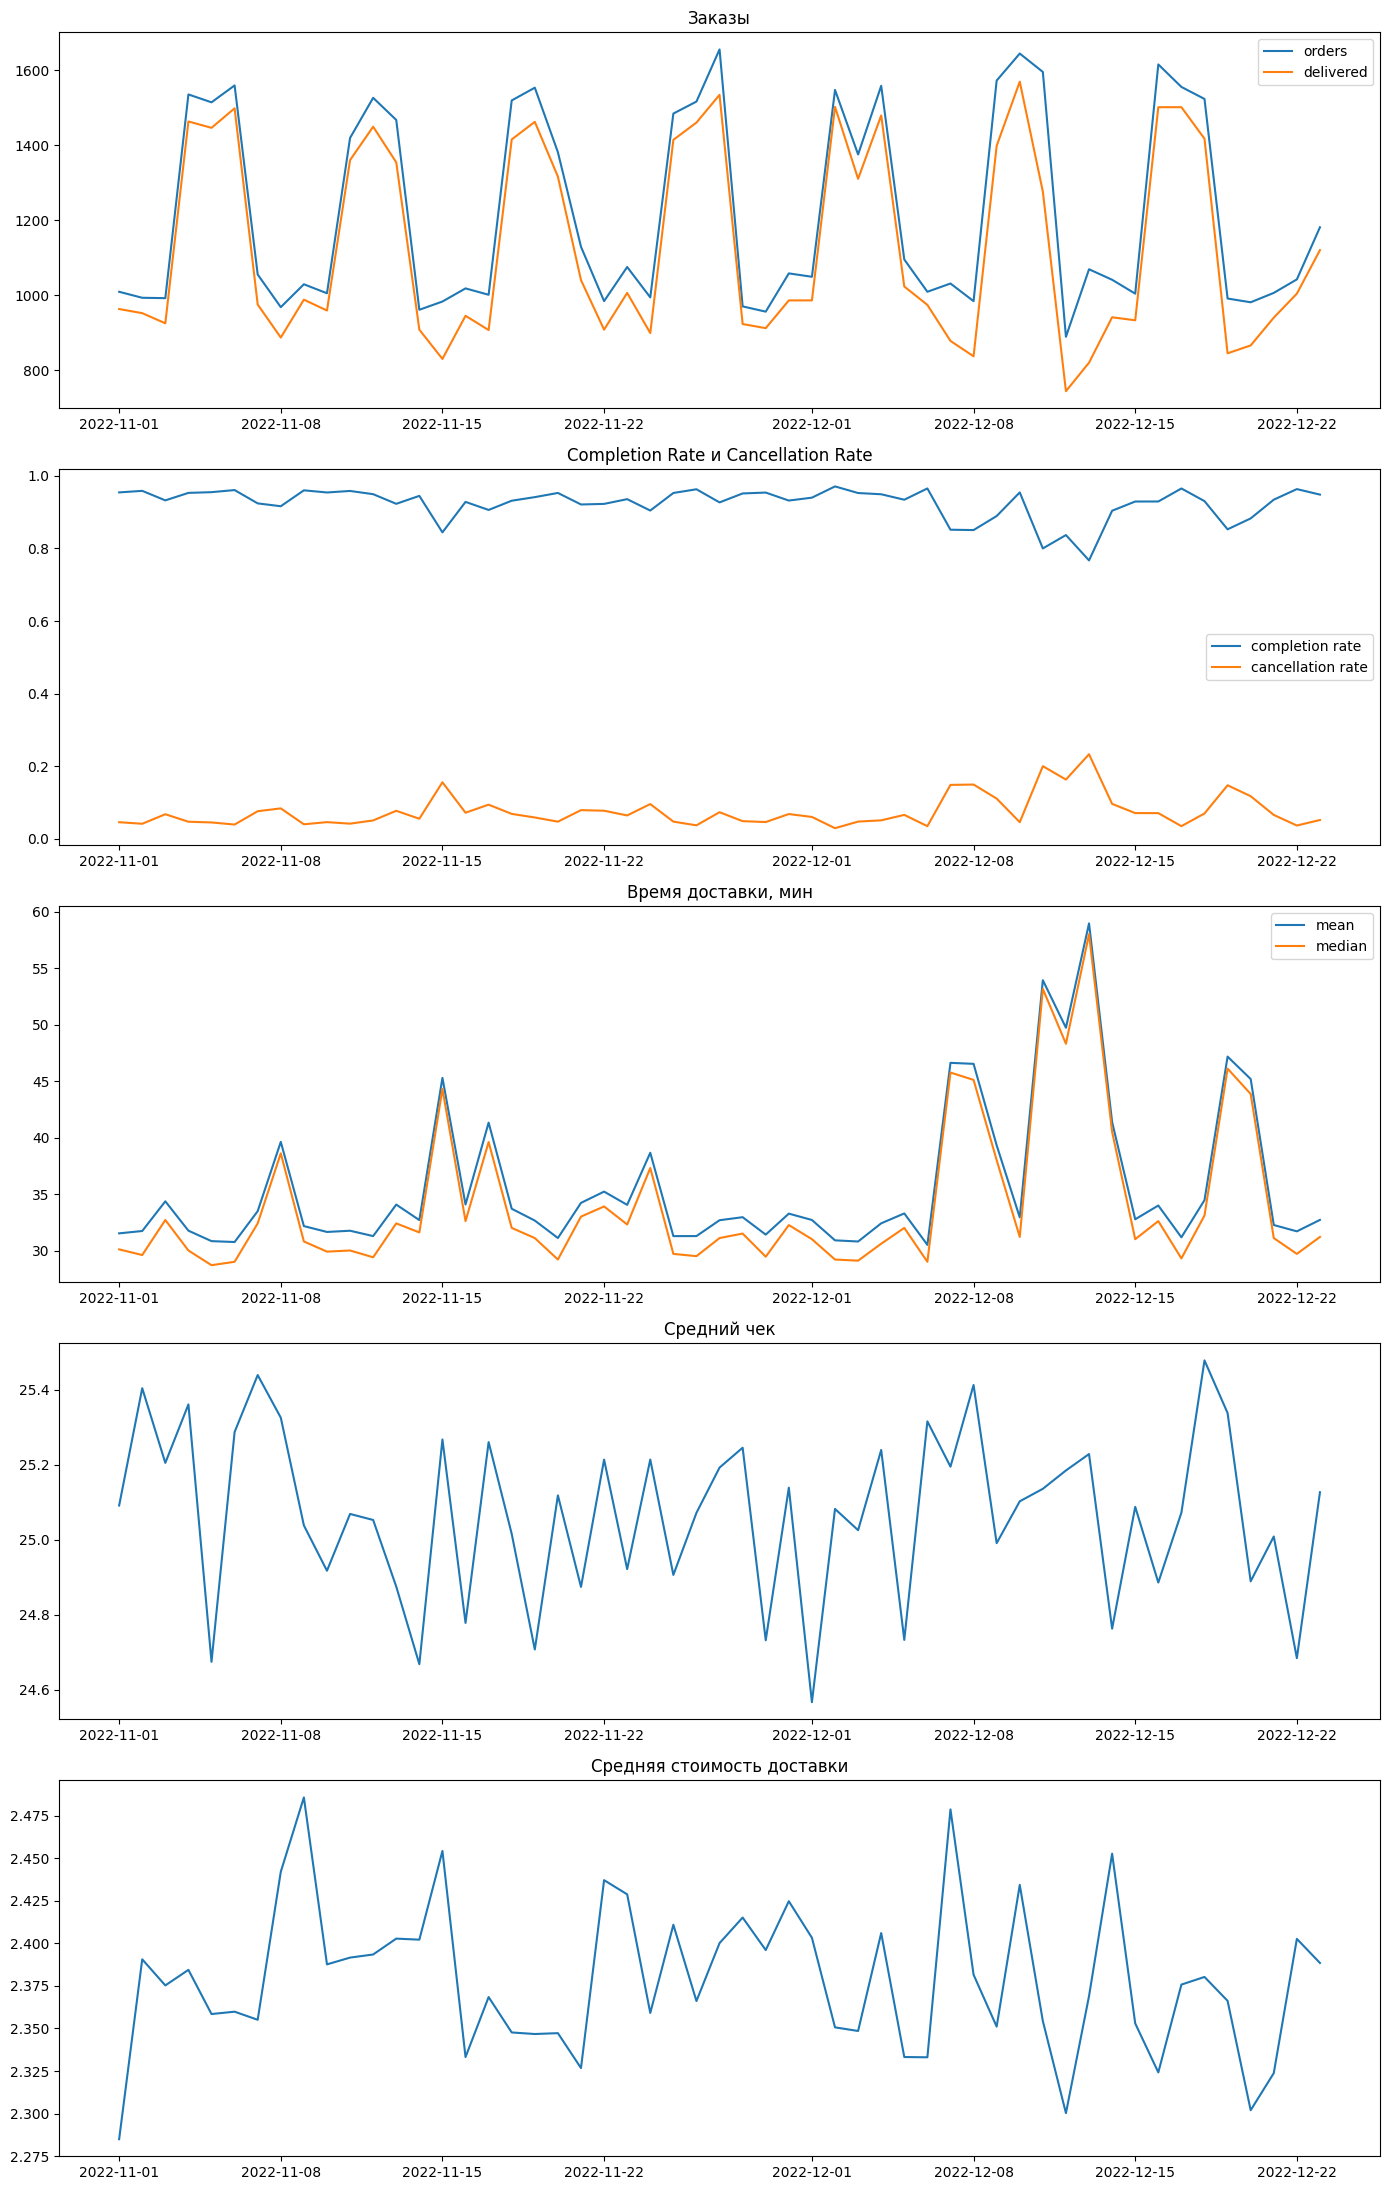

In [10]:
fig, axes = plt.subplots(5, 1, figsize=(14, 22))
axes[0].plot(daily['date'], daily['orders'], label='orders')
axes[0].plot(daily['date'], daily['delivered'], label='delivered')
axes[0].set_title('Заказы')
axes[0].legend()
axes[1].plot(daily['date'], daily['completion_rate'], label='completion rate')
axes[1].plot(daily['date'], daily['cancellation_rate'], label='cancellation rate')
axes[1].set_title('Completion Rate и Cancellation Rate')
axes[1].legend()
axes[2].plot(daily['date'], daily['avg_delivery_min'], label='mean')
axes[2].plot(daily['date'], daily['median_delivery_min'], label='median')
axes[2].set_title('Время доставки, мин')
axes[2].legend()
axes[3].plot(daily['date'], daily['avg_order_value'])
axes[3].set_title('Средний чек')
axes[4].plot(daily['date'], daily['avg_delivery_fee'])
axes[4].set_title('Средняя стоимость доставки')
plt.tight_layout()
plt.show()

In [11]:
daily

,date,orders,delivered,cancelled,avg_delivery_min,median_delivery_min,avg_order_value,avg_delivery_fee,completion_rate,cancellation_rate
0,2022-11-01,1009,963,46,31.517445,30.10,25.091615,2.284965,0.954410,0.045590
1,2022-11-02,993,952,41,31.725630,29.60,25.404552,2.390564,0.958711,0.041289
2,2022-11-03,992,925,67,34.353622,32.70,25.205383,2.375252,0.932460,0.067540
3,2022-11-04,1535,1463,72,31.755707,30.00,25.361316,2.384384,0.953094,0.046906
4,2022-11-05,1514,1446,68,30.828907,28.70,24.674485,2.358448,0.955086,0.044914
5,2022-11-06,1559,1498,61,30.750668,29.00,25.287691,2.359827,0.960872,0.039128
6,2022-11-07,1055,975,80,33.482872,32.40,25.439659,2.355071,0.924171,0.075829
7,2022-11-08,968,887,81,39.615333,38.60,25.326043,2.441963,0.916322,0.083678
8,2022-11-09,1029,988,41,32.160931,30.80,25.038562,2.485627,0.960155,0.039845
9,2022-11-10,1005,959,46,31.641710,29.90,24.917562,2.387602,0.954229,0.045771


**Вывод**: Выраженного тренда нет. Число заказов держится на одном уровне: в среднем около 1210 в день в ноябре и около 1250 в декабре. Есть сильная недельная сезонность: в пятницу, субботу и воскресенье примерно 1500 заказов, в будни около 1000. Средний чек (около 25) и средняя стоимость доставки (около 2.4) весь период почти не меняются.

При этом в декабре стало хуже с отменами и временем доставки. Средний Cancellation Rate вырос с 6.3% в ноябре до 8.8% в декабре.

Подозрительные на аномалии дни, когда отмены и время доставки резко растут одновременно:

15.11: отмены 15.6%, среднее время доставки 45 мин;
07.12 и 08.12: отмены около 15%, доставка около 46.5 мин;
11.12-13.12: самый сильный провал, отмены до 23.3% и доставка до 59 мин 13.12;
19.12-20.12: отмены 12-15%, доставка около 45-47 мин;
25.12: отмены 15.1%, доставка около 51 мин.

Среднее и медианное время доставки двигаются вместе, значит, рост происходит во всех заказах в эти дни, а не из-за отдельных выбросов. Похоже, что в эти дни что-то происходит с операционной частью, например не хватает курьеров. Проверю это в следующих пунктах.

#### 2. Выявление аномалий — 3 балла
Проверьте построенные дневные ряды следующих метрик на аномальность:
- Число заказов, число доставленных заказов;
- Completion Rate, Cancellation Rate;
- Время доставки (среднее и медиана).

Для метрик, в которых визуально заметна недельная сезонность (абсолютные метрики), используйте STL-разложение + 3σ, для других — просто 3σ (вы проводите ретроспективный анализ, а не имитируете онлайн-проверку, не забывайте об этом в реализации).

Дайте короткий комментарий по результатам проверки.

In [ ]:
# your code is here

#### 3. Поиск причин аномального поведения (шаг 1) — 3 балла
Разложим метрики, в которых обнаружены аномалии, на составляющие.

Визуализируйте:
- Отмены в разрезе причин (абсолютная метрика);
- Длительность этапов, из которых складывается итоговая продолжительность доставки (time_to_assign_courier_min, actual_preparation_time_min, travel_time_min). Берите среднее или медиану на ваш выбор.

Есть ли какие-нибудь закономерности?

In [12]:
def three_sigma(x):
    mean = x.mean()
    std = x.std()
    return (x > mean + 3 * std) | (x < mean - 3 * std)

In [13]:
s = daily.set_index('date')
s.index = pd.to_datetime(s.index)

In [14]:
anomalies = {}
for metric in ['orders', 'delivered']:
    resid = STL(s[metric], period=7).fit().resid
    anomalies[metric] = resid[three_sigma(resid)].index.date.tolist()

for metric in ['completion_rate', 'cancellation_rate', 'avg_delivery_min', 'median_delivery_min']:
    anomalies[metric] = s[three_sigma(s[metric])].index.date.tolist()

In [15]:
anomalies

{'orders': [],
 'delivered': [],
 'completion_rate': [datetime.date(2022, 12, 13)],
 'cancellation_rate': [datetime.date(2022, 12, 13)],
 'avg_delivery_min': [datetime.date(2022, 12, 13)],
 'median_delivery_min': [datetime.date(2022, 12, 13)]}

**Вывод**: границы считал по всему ряду сразу, без скользящего окна, потому что это ретроспективный анализ.

В числе заказов и доставленных заказов после удаления недельной сезонности и тренда аномалий нет, то есть спрос стабильный. Все относительные метрики и время доставки показывают аномалию в один и тот же день, 13.12: Cancellation Rate 23.3% и среднее время доставки около 59 минут.

Другие плохие дни из первого пункта (07-08.12, 11-12.12, 19-20.12, 25.12) за 3σ не вышли. Они повторяются часто и сами раздувают стандартное отклонение, поэтому границы получаются широкими. Значит, проблема не в одном случайном дне: в декабре регулярно бывают дни с ростом отмен и задержек при нормальном спросе.

#### 4. Поиск причин аномального поведения (шаг 2) — 3 балла
Постройте динамику метрик, в которых обнаружены аномалии, по базовым срезам (можете выбрать что-то одно: Completion Rate или Cancellation Rate, среднее время доставки или медиана времени доставки):
- платформа (iOS, Android);
- район адреса доставки;
- сегмент пользователя (новые / повторные);
- признак промо акции.

Выделяется ли какой-то сегмент, где аномалия выражена сильнее?

In [16]:
df['cancelled'] = (df['status'] == 'cancelled').astype(int)
slices = ['platform', 'city_region', 'user_segment', 'promotion_used']

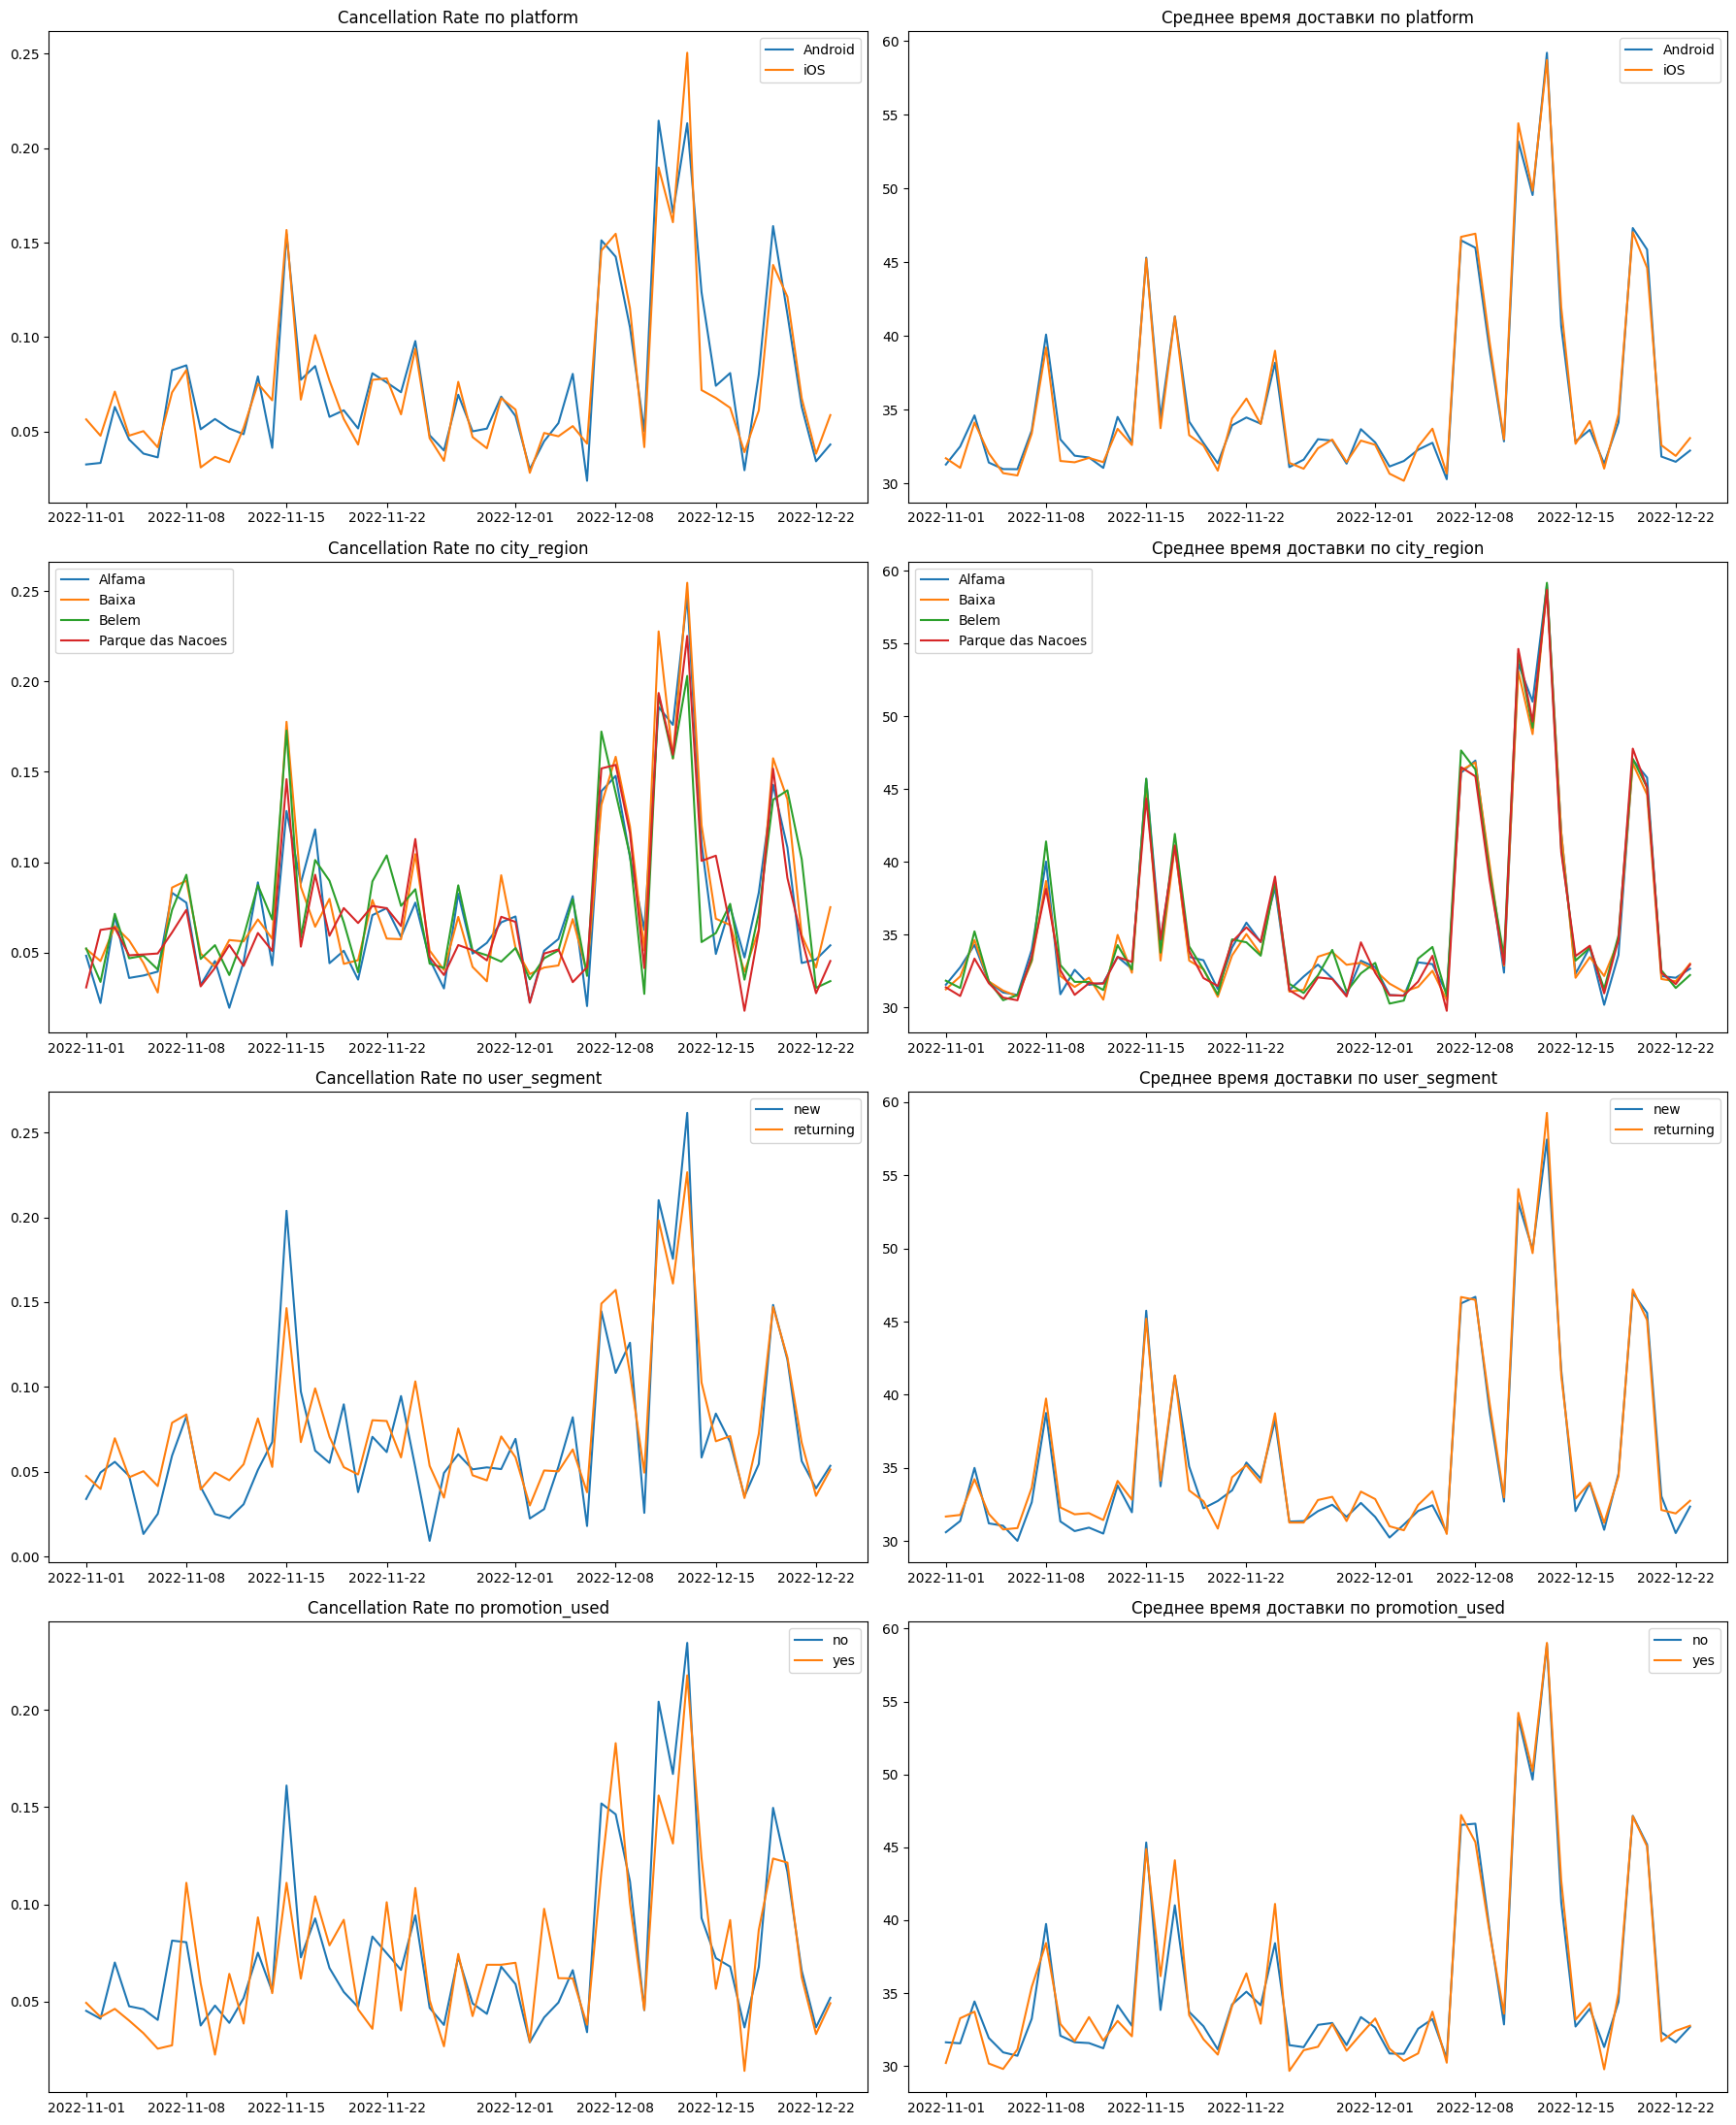

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))
for i, col in enumerate(slices):
    g = df.groupby(['date', col]).agg(
        cancellation_rate=('cancelled', 'mean'),
        avg_delivery_min=('delivery_min', 'mean')
    ).reset_index()
    for val in g[col].unique():
        part = g[g[col] == val]
        axes[i, 0].plot(part['date'], part['cancellation_rate'], label=val)
        axes[i, 1].plot(part['date'], part['avg_delivery_min'], label=val)
    axes[i, 0].set_title('Cancellation Rate по ' + col)
    axes[i, 1].set_title('Среднее время доставки по ' + col)
    axes[i, 0].legend()
    axes[i, 1].legend()
plt.tight_layout()
plt.show()

In [18]:
bad_days = pd.to_datetime(['2022-11-15', '2022-12-07', '2022-12-08', '2022-12-11', '2022-12-12',
                           '2022-12-13', '2022-12-19', '2022-12-20', '2022-12-25']).date
df['bad_day'] = df['date'].isin(bad_days)

for col in slices:
    display(df.groupby([col, 'bad_day']).agg(
        cancellation_rate=('cancelled', 'mean'),
        avg_delivery_min=('delivery_min', 'mean')
    ).unstack().round(3))

cancellation_rate        avg_delivery_min        
bad_day              False  True             False   True 
platform                                                  
Android              0.059  0.168           33.126  49.295
iOS                  0.058  0.167           33.108  49.488

cancellation_rate        avg_delivery_min        
bad_day                       False  True             False   True 
city_region                                                        
Alfama                        0.057  0.162           33.102  49.521
Baixa                         0.060  0.180           33.130  49.055
Belem                         0.060  0.166           33.242  49.673
Parque das Nacoes             0.057  0.162           32.990  49.349

cancellation_rate        avg_delivery_min        
bad_day                  False  True             False   True 
user_segment                                                  
new                      0.052  0.176           32.829  49.209
returning                0.060  0.166           33.167  49.437

cancellation_rate        avg_delivery_min        
bad_day                    False  True             False   True 
promotion_used                                                  
no                         0.058  0.170           33.120  49.414
yes                        0.060  0.145           33.076  49.285

**Вывод**: ни один сегмент не выделяется. Во всех срезах (платформа, район, новые и повторные пользователи, промо) линии на графиках почти совпадают, и пики отмен и времени доставки приходятся на одни и те же дни. В плохие дни Cancellation Rate растёт примерно с 6% до 15-18%, а время доставки примерно с 33 до 49-50 минут одинаково во всех сегментах. Небольшие различия, например у новых пользователей или в районе Baixa, укладываются в шум, потому что эти сегменты маленькие.

Значит, проблема не связана с конкретной платформой, районом или типом пользователя. Она затрагивает весь сервис сразу, скорее всего на стороне операционки: курьеры или рестораны.

#### 5. Поиск причин аномального поведения (шаг 3) — 3 балла

Постройте динамику структуры заказов в разрезе сегментов:
- доля заказов по платформам;
- доля заказов по регионам города;
- доля заказов по сегменту пользователя;
- доля заказов по признаку промо акции.

Сравните даты аномалий с динамикой долей. Может ли изменение структуры объяснить падение метрик?

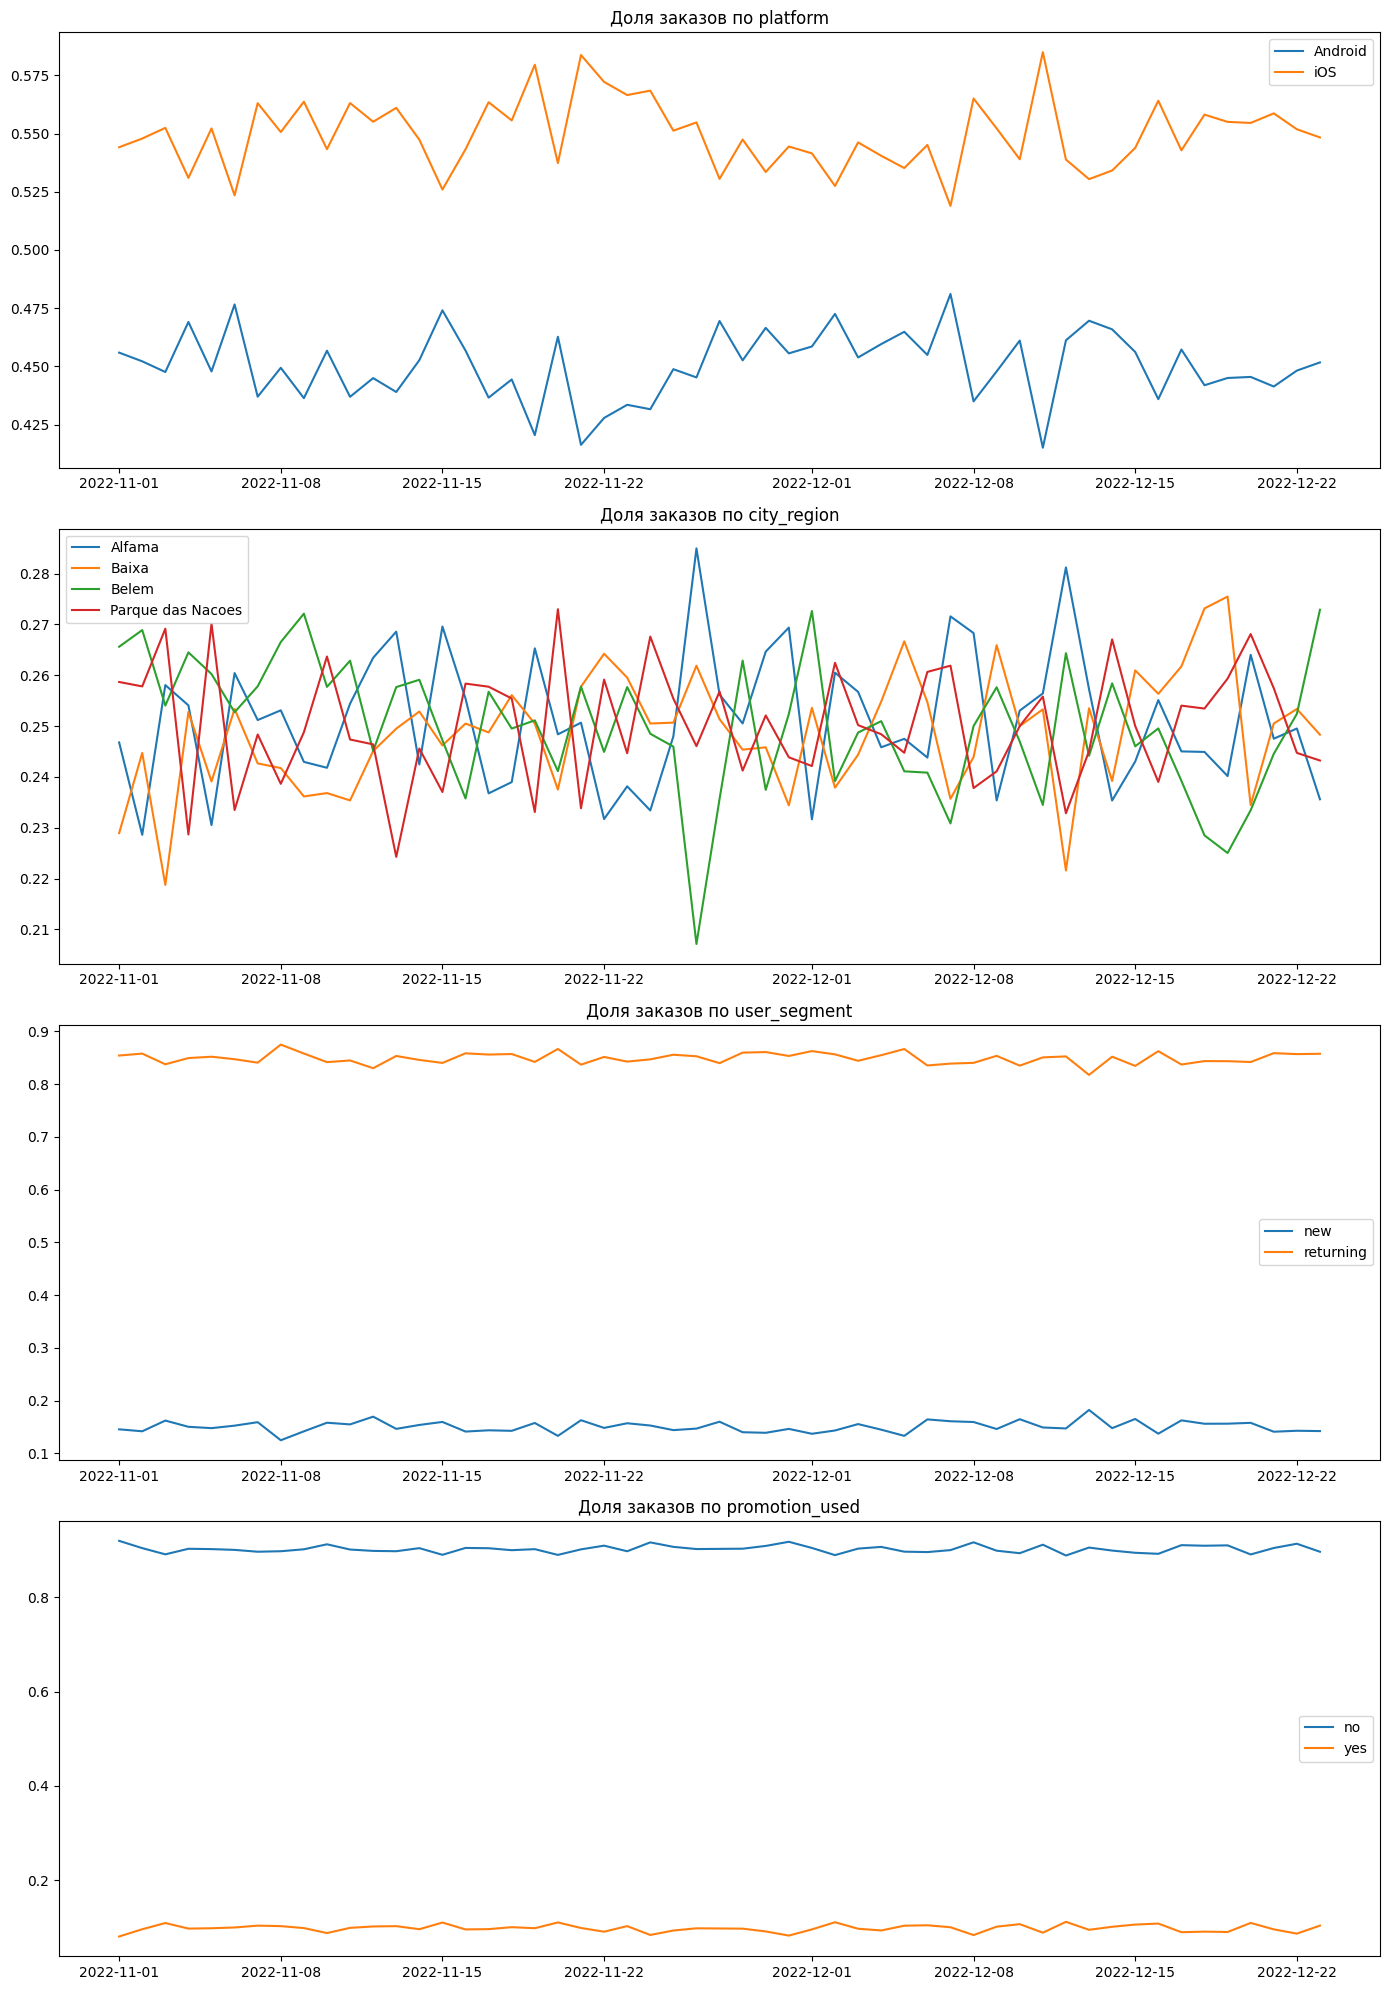

In [20]:
fig, axes = plt.subplots(4, 1, figsize=(14, 20))
for ax, col in zip(axes, slices):
    share = pd.crosstab(df['date'], df[col], normalize='index')
    for val in share.columns:
        ax.plot(share.index, share[val], label=val)
    ax.set_title('Доля заказов по ' + col)
    ax.legend()
plt.tight_layout()
plt.show()

In [21]:
for col in slices:
    display(pd.crosstab(df['bad_day'], df[col], normalize='index').round(3))

platform,Android,iOS
bad_day,,
False,0.450,0.550
True,0.451,0.549


city_region,Alfama,Baixa,Belem,Parque das Nacoes
bad_day,,,,
False,0.250,0.250,0.251,0.25
True,0.263,0.246,0.240,0.25


user_segment,new,returning
bad_day,,
False,0.150,0.850
True,0.159,0.841


promotion_used,no,yes
bad_day,,
False,0.902,0.098
True,0.903,0.097


**Вывод**: структура заказов весь период стабильна: примерно 55% iOS и 45% Android, районы около 25% каждый, около 15% новых пользователей и около 10% заказов с промо. В дни аномалий доли не меняются: отклонения в пределах 1 п.п., как и в обычные дни.

Изменение структуры не может объяснить падение метрик. Во-первых, сами доли не сдвигаются. Во-вторых, в прошлом пункте метрики ухудшались одинаково во всех сегментах, так что даже при сдвиге долей эффекта не было бы. Причину нужно искать не в составе заказов, а в процессе доставки: время назначения курьера, время приготовления, время в пути.

#### 6. Поиск причин аномального поведения (шаг 4) — 3 балла
Разложение метрик на срезы не принесло результатов. Может быть причина аномалий лежит вне продукта?

Получите данные о погоде по API за весь анализируемый период по дням. Для этого используйте [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?daily=temperature_2m_mean,wind_speed_10m_max,precipitation_sum) от Open-Meteo (регистрация и получение ключа не требуется, по ссылке есть пример запроса на Python).

- Для координат выгрузки возьмите: latitude: 38.736946, longitude: -9.142685;
- Timezone — auto;
- daily значения temperature_2m_mean, precipitation_sum, wind_speed_10m_max.

Соберите датасет с колонками: день, средняя температура воздуха, максимальная скорость ветра, суммарное количество осадков.

In [26]:
url = 'https://archive-api.open-meteo.com/v1/archive'
params = {
    'latitude': 38.736946,
    'longitude': -9.142685,
    'start_date': '2022-11-01',
    'end_date': '2022-12-31',
    'daily': 'temperature_2m_mean,precipitation_sum,wind_speed_10m_max',
    'timezone': 'auto'
}

response = requests.get(url, params=params)
weather_json = response.json()

weather = pd.DataFrame({
    'date': pd.to_datetime(weather_json['daily']['time']).date,
    'temperature_mean': weather_json['daily']['temperature_2m_mean'],
    'wind_speed_max': weather_json['daily']['wind_speed_10m_max'],
    'precipitation_sum': weather_json['daily']['precipitation_sum']
})

weather

,date,temperature_mean,wind_speed_max,precipitation_sum
0,2022-11-01,15.8,16.1,0.0
1,2022-11-02,14.8,14.8,0.0
2,2022-11-03,17.5,23.1,4.2
3,2022-11-04,15.8,15.5,0.0
4,2022-11-05,14.1,9.7,0.0
...,...,...,...,...
56,2022-12-27,13.7,10.0,0.0
57,2022-12-28,13.4,15.0,0.1
58,2022-12-29,15.9,26.4,2.7
59,2022-12-30,16.5,26.9,0.5


#### 7. Поиск причин аномального поведения (шаг 5) — 3 балла
Объедините датасет метрик, в которых найдены аномалии, с датасетом погоды.    
Для каждой метрики постройте совместные визуализации данных погоды и продуктовой метрики.

Сформулируйте гипотезу — что могло повлиять на падение конверсии в дни аномалий? Как конверсия связана с другими метриками, для которых вы  обнаружили аномальные значения? Какую роль в изменении метрик могла сыграть погода?

In [27]:
weather['date'] = pd.to_datetime(weather['date']).dt.date
data = daily[['date', 'completion_rate', 'cancellation_rate', 'avg_delivery_min']].merge(weather, on='date')

metrics_anom = ['completion_rate', 'cancellation_rate', 'avg_delivery_min']
weather_cols = ['precipitation_sum', 'wind_speed_max', 'temperature_mean']

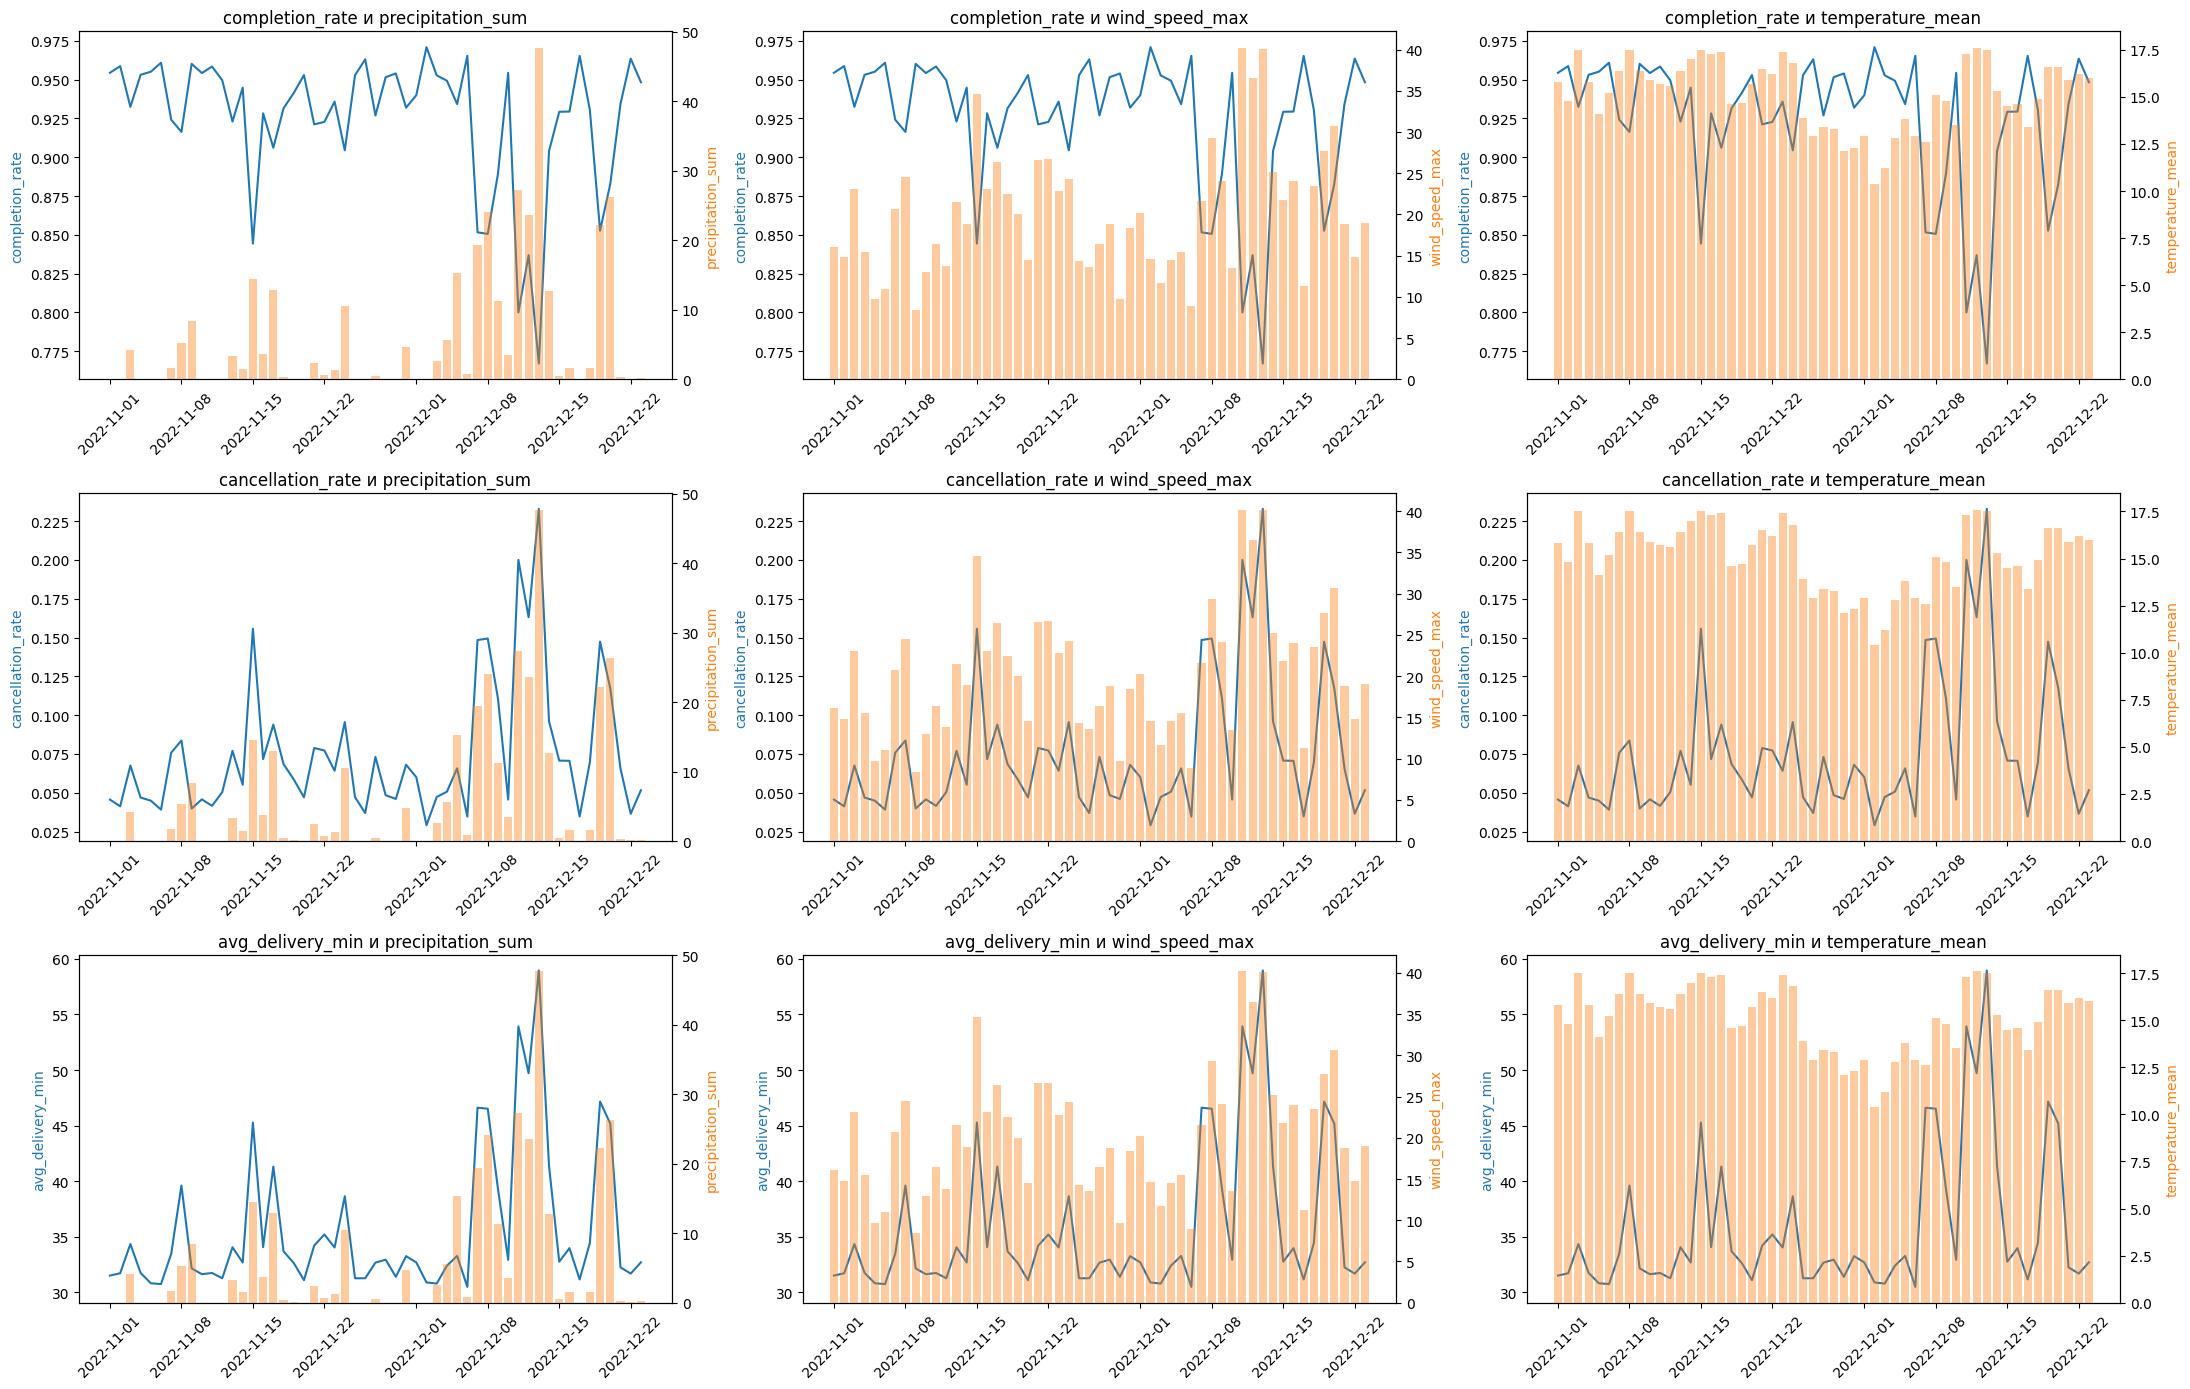

In [28]:
fig, axes = plt.subplots(3, 3, figsize=(22, 14))
for i, metric in enumerate(metrics_anom):
    for j, w in enumerate(weather_cols):
        ax = axes[i, j]
        ax.plot(data['date'], data[metric], color='tab:blue')
        ax.set_ylabel(metric, color='tab:blue')
        ax2 = ax.twinx()
        ax2.bar(data['date'], data[w], color='tab:orange', alpha=0.4)
        ax2.set_ylabel(w, color='tab:orange')
        ax.set_title(metric + ' и ' + w)
        ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [29]:
data[metrics_anom + weather_cols].corr().loc[metrics_anom, weather_cols].round(2)

,precipitation_sum,wind_speed_max,temperature_mean
completion_rate,-0.91,-0.89,-0.44
cancellation_rate,0.91,0.89,0.44
avg_delivery_min,0.94,0.87,0.44


**Гипотеза**: падение конверсии в доставку в дни аномалий вызвано плохой погодой: сильными дождями и ветром.

Все дни с аномалиями совпадают с днями, когда осадков больше 10 мм и ветер сильнее 25-30 км/ч: 15.11, 07-08.12, 11-13.12, 19-20.12, 25.12. Самый плохой день, 13.12, совпадает с максимумом осадков за период (47.7 мм) и ветром около 40 км/ч. Корреляция Cancellation Rate и времени доставки с осадками и ветром около 0.9. С температурой связь слабее, она в эти дни просто немного выше, потому что дождливые дни в Лиссабоне теплее.

Конверсия связана с временем доставки: в те же дни, когда падает Completion Rate, среднее время доставки вырастает до 45-59 минут. Скорее всего, цепочка такая: в дождь и ветер курьерам сложнее ехать и их не хватает, заказы дольше ждут назначения и дольше в пути, время доставки растёт, и часть пользователей отменяет заказ или заказ отменяется из-за отсутствия курьера.

Спрос при этом не падает: число заказов в эти дни обычное, и все сегменты страдают одинаково, что тоже указывает на внешнюю причину. Интересно, что 05.12 был сильный дождь (15.3 мм), но слабый ветер, и отмен почти не было. Значит, сильнее всего влияет сочетание дождя и ветра.

#### 8. Влияние на бизнес-результат — 3 балла
Примените один из методов декомпозиции из разобранных в первом семинаре, чтобы оценить вклад изменения конверсии и числа заказов в изменение числа доставок в декабре относительно ноября (MoM анализ).    

Постройте waterfall диаграмму.

Выпишите дни, которые внесли наибольший вклад в падение среднемесячной конверсии декабря относительно ноября. Пересекаются ли эти даты с датами повышенного числа осадков? Сделайте выводы.

In [ ]:
# your code is here

####  9. Анализ 24/7 — 3 балла

Одним из распространенных разрезов анализа метрик продуктов с внутринедельной сезонностью является разложение по дням недели и часам.

Постройте матрицу 24/7 (часы - дни недели) для ноября и декабря (в ячейку матрицы должно попасть агрегированное значение метрики для дня недели и часа), но перед этим очистите декабрьские значения от аномалий — для стабильной оценки нам нужны метрики без влияния экстремальной погоды.

Визуализацию стройте для:
- Числа заказов (всех);
- Completion Rate;
- Среднего или медианного времени доставки.

Подумайте, почему в определенные часы / дни недели мы наблюдаем падение конверсии? Как меняются остальные метрики?    
При ответе опирайтесь на статистические понятия — в какие-то часы просадка или, напротив, слишком высокая конверсия может быть не закономерностью, а случайностью из-за эффекта низкой базы в это время.

In [30]:
daily['month'] = pd.to_datetime(daily['date']).dt.month
monthly = daily.groupby('month')[['orders', 'delivered']].sum()
monthly['cr'] = monthly['delivered'] / monthly['orders']

In [31]:
o1, o2 = monthly.loc[11, 'orders'], monthly.loc[12, 'orders']
cr1, cr2 = monthly.loc[11, 'cr'], monthly.loc[12, 'cr']
d1, d2 = monthly.loc[11, 'delivered'], monthly.loc[12, 'delivered']

In [32]:
orders_effect = (o2 - o1) * cr1
cr_effect = o2 * (cr2 - cr1)

In [33]:
monthly

,orders,delivered,cr
month,,,
11,36308,34084,0.938746
12,28356,25864,0.912117


In [34]:
orders_effect

np.float64(-7464.910432962433)

In [35]:
cr_effect

np.float64(-755.0895670375694)

In [36]:
fig = go.Figure(go.Waterfall(
    x=['Доставки ноябрь', 'Эффект числа заказов', 'Эффект конверсии', 'Доставки декабрь'],
    measure=['absolute', 'relative', 'relative', 'total'],
    y=[d1, orders_effect, cr_effect, d2],
    text=[d1, round(orders_effect), round(cr_effect), d2],
    textposition='outside'
))
fig.update_layout(title='Декомпозиция изменения числа доставок, декабрь vs ноябрь', yaxis_range=[30000, 38000])
fig.show()

In [37]:
dec = daily[daily['month'] == 12].copy()
dec['contribution'] = (dec['delivered'] - cr1 * dec['orders']) / o2
dec = dec.merge(weather, on='date')

dec.sort_values('contribution')[['date', 'orders', 'completion_rate', 'contribution', 'precipitation_sum', 'wind_speed_max']].head(10)

,date,orders,completion_rate,contribution,precipitation_sum,wind_speed_max
10,2022-12-11,1595,0.800000,-0.007804,27.3,40.2
12,2022-12-13,1069,0.767072,-0.006472,47.7,40.1
11,2022-12-12,889,0.836895,-0.003193,23.6,36.5
6,2022-12-07,1031,0.851600,-0.003169,19.4,21.6
7,2022-12-08,984,0.850610,-0.003058,24.1,29.3
18,2022-12-19,991,0.852674,-0.003008,22.2,27.7
8,2022-12-09,1572,0.889313,-0.002740,11.3,24.1
19,2022-12-20,981,0.882773,-0.001936,26.3,30.7
13,2022-12-14,1041,0.903939,-0.001278,12.7,25.2
15,2022-12-16,1615,0.929412,-0.000532,1.6,24.0


**Выводы**: число доставок в декабре выросло на 1253 по сравнению с ноябрём, но только за счёт роста числа заказов (+2230). Падение конверсии с 93.9% до 91.4% забрало около 977 доставок, то есть почти половину прироста.

Девять дней с наибольшим вкладом в падение конверсии (11, 13, 25, 12, 7, 8, 19, 9 и 20 декабря) полностью совпадают с днями, когда осадков было больше 10 мм, а ветер обычно больше 25 км/ч. В сумме эти дни дают около −0.026, это даже больше общего падения конверсии (−0.025). Значит, в остальные дни конверсия была на уровне ноября или выше. Сильнее всего просели 11.12 и 25.12: это выходные с большим числом заказов, поэтому падение конверсии в них стоило больше всего доставок.

Получается, что почти всё снижение конверсии в декабре объясняется дождливыми и ветреными днями, а не постоянной проблемой в продукте.

####   10. Предложение по улучшению продукта — 3 балла
Базовым подходом для оптимизации работы в часы пик в доставке является динамическое ценообразование. В продукте эта механика еще не реализована. Вы смотрите на данные и решаете, что это отличная инициатива для планирования следующего квартала.

*Динамическое ценообразование помогает не только сглаживать часы повышенного спроса, но и регулировать работу продукта при внешних влияниях, когда пик спроса предсказать невозможно. В данном кейсе мы не рассматриваем такие решения, т.к. не стремимся написать алгоритм динамического прайсинга, а хотим провести базовое исследование проблем и поиск инициативы под быструю реализацию и тест. Поэтому в дальнейших заданиях речь идет исключительно о часах повышенного спроса, очищенных от аномалий.*

Чтобы протестировать гипотезу, достаточно простого подхода — увеличивать стоимость доставки на фиксированный процент (например, на 20%) в определенные дни недели-часы.

- На основе построенных в предыдущем задании матриц, предложите, в какие дни недели / часы вы порекомендуете увеличить стоимость доставки.
- Для каждого месяца рассчитайте долю заказов от общего числа, который будет иметь повышенную стоимость, согласно предложенным вами правилам повышения.

In [38]:
df['cancelled'] = (df['status'] == 'cancelled').astype(int)
df['hour'] = df['order_time'].dt.hour
df['dow'] = df['order_time'].dt.dayofweek

In [39]:
anomaly_days = pd.to_datetime(['2022-11-15', '2022-12-07', '2022-12-08', '2022-12-09', '2022-12-11',
                               '2022-12-12', '2022-12-13', '2022-12-19', '2022-12-20', '2022-12-25']).date
clean = df[~df['date'].isin(anomaly_days)]

In [40]:
n_days = clean.groupby('dow')['date'].nunique()
orders_matrix = clean.pivot_table(index='dow', columns='hour', values='order_id', aggfunc='count').div(n_days, axis=0)
cancel_matrix = clean.pivot_table(index='dow', columns='hour', values='cancelled', aggfunc='mean')
delivery_matrix = clean.pivot_table(index='dow', columns='hour', values='delivery_min', aggfunc='mean')

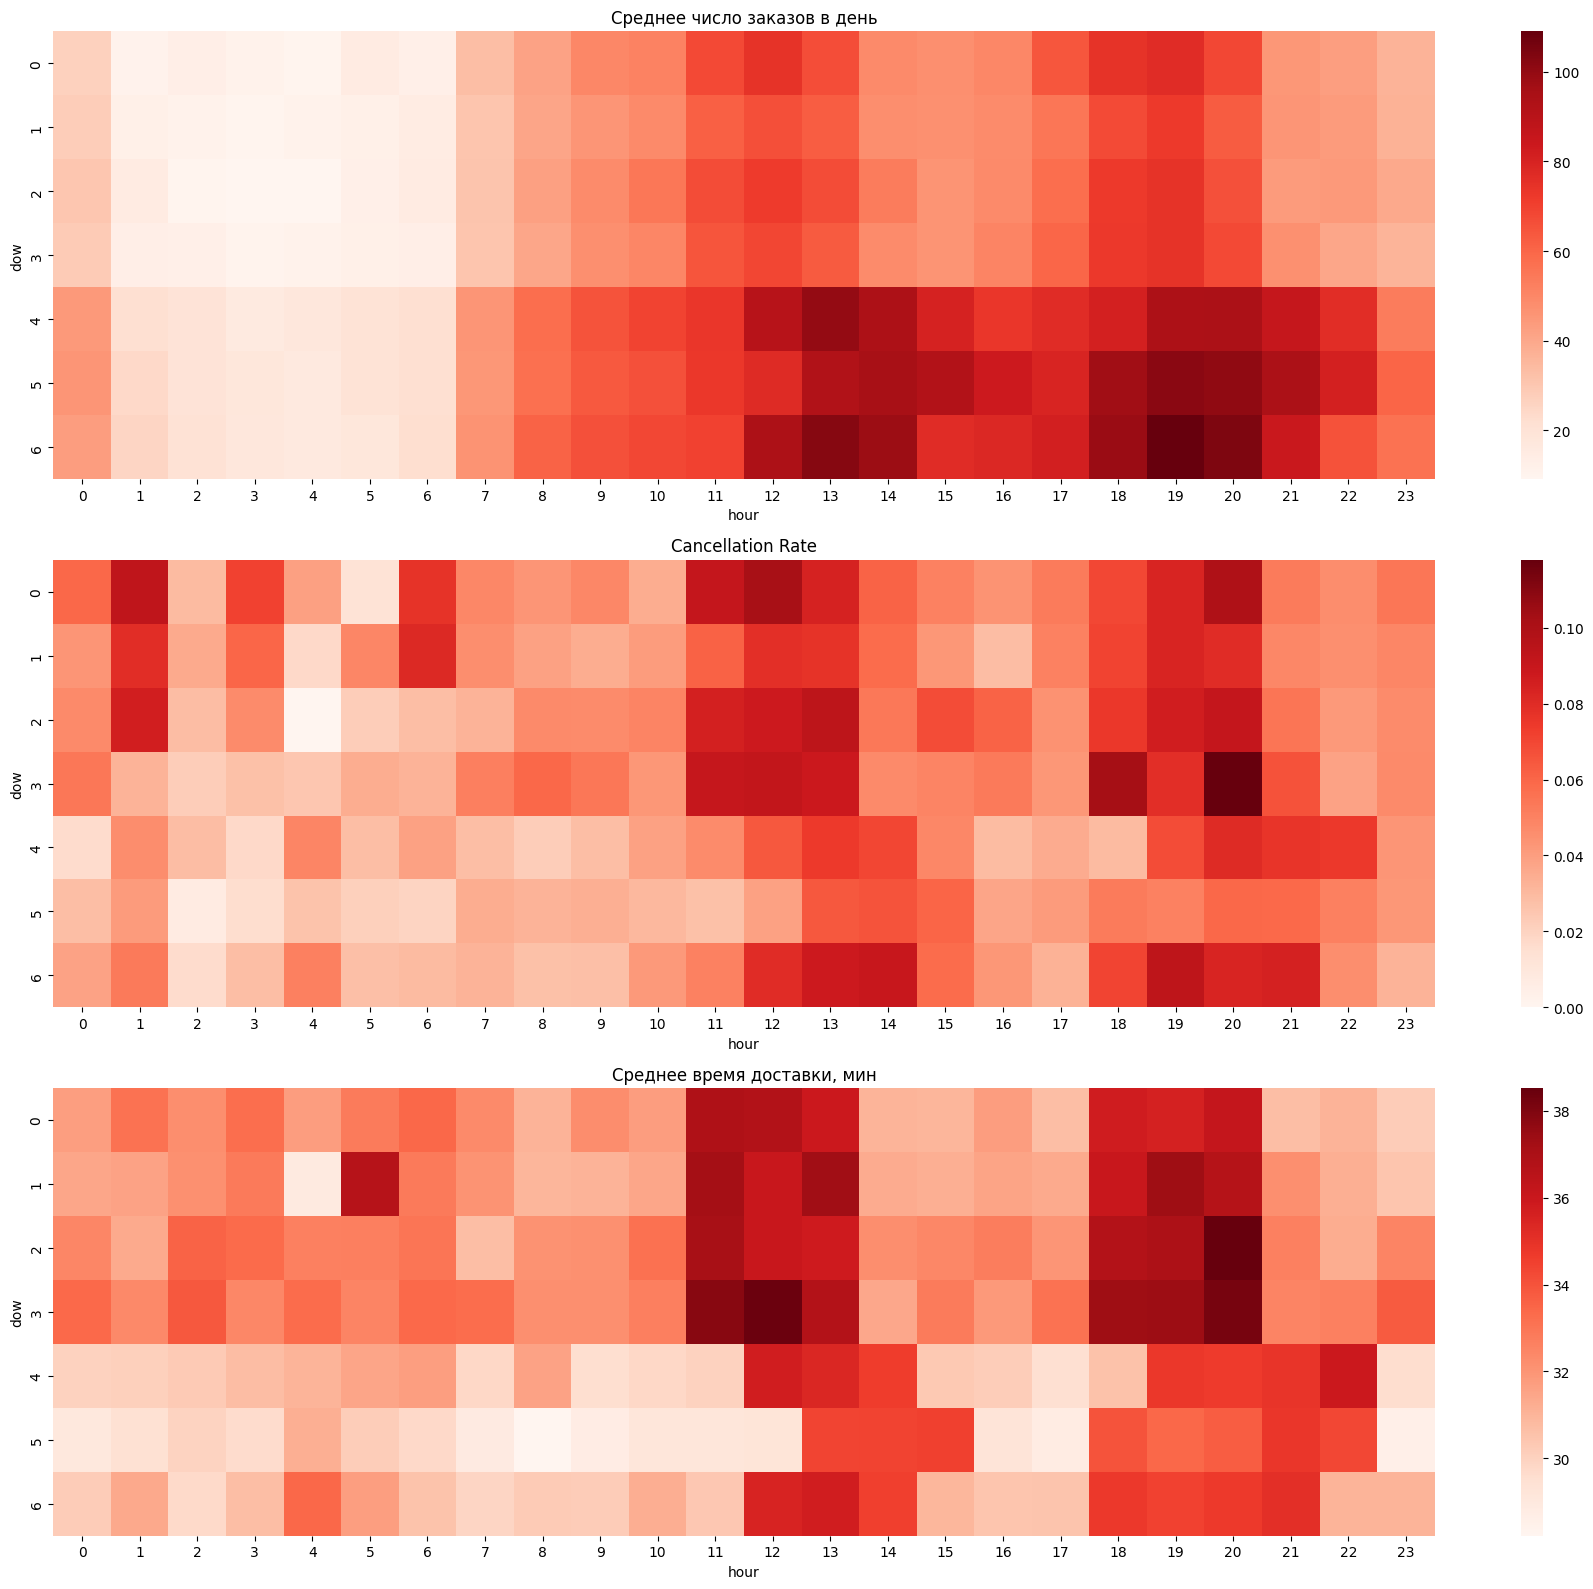

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(18, 16))
sns.heatmap(orders_matrix, ax=axes[0], cmap='Reds')
axes[0].set_title('Среднее число заказов в день')
sns.heatmap(cancel_matrix, ax=axes[1], cmap='Reds')
axes[1].set_title('Cancellation Rate')
sns.heatmap(delivery_matrix, ax=axes[2], cmap='Reds')
axes[2].set_title('Среднее время доставки, мин')
plt.tight_layout()
plt.show()

In [42]:
peak_hours = {
    0: [11, 12, 13, 18, 19, 20],
    1: [11, 12, 13, 18, 19, 20],
    2: [11, 12, 13, 18, 19, 20],
    3: [11, 12, 13, 18, 19, 20],
    4: [12, 13, 14, 19, 20, 21, 22],
    5: [13, 14, 15, 18, 19, 20, 21, 22],
    6: [12, 13, 14, 18, 19, 20, 21]
}

df['surge'] = df.apply(lambda r: r['hour'] in peak_hours[r['dow']], axis=1)
df['month'] = df['order_time'].dt.month
df.groupby('month')['surge'].mean()

,surge
month,
11,0.436350
12,0.440965


**Вывод**: под повышенную стоимость попадёт около 44% заказов. Это много, потому что в пиковые часы как раз сосредоточена большая часть спроса. В эти часы Cancellation Rate в среднем 8.1% против 4.2% в остальное время, а время доставки 35.9 минут против 31.2. Если такая доля покажется бизнесу слишком большой, для первого теста можно оставить только самые загруженные часы: вечерний пик 18-21 во все дни и обеденный пик в выходные.

### Часть 2. Дизайн эксперимента

Ваше предложение понравилось команде. Бэклог инициатив собран, время планировать роадмап. Вас просят провести дизайн эксперимента повышения стоимости доставки на 20% в регулярные часы повышенного спроса, чтобы команда поняла, сколько времени понадобится для получения результатов.

#### 1. Формат эксперимента — 3 балла

Выберите и обоснуйте единицу рандомизации теста:
- по-юзерный A/B тест,
- свитчбек по времени (например, 30-минутки);
- региональный A/B тест.

Вы отвечали на тестовый вопрос о такой же инициативе в ДЗ 3, возможно, это поможет определиться.

In [ ]:
# your answer is here

**Выбор**: свитчбек по времени, например 30-минутные слоты в пиковые часы, где каждый слот случайно попадает в тест (+20% к стоимости доставки) или в контроль. Это совпадает с ответом из ДЗ 3, где динамическое ценообразование в доставке еды мы отнесли к свитчбеку.

**Почему не по-юзерный A/B тес**т. Все пользователи делят один пул курьеров. Если тестовая группа из-за высокой цены будет заказывать меньше, освободившиеся курьеры быстрее доставят заказы контрольной группе. Контроль станет лучше, чем был бы без теста, и эффект на отмены и время доставки получится смещённым (нарушается независимость групп). К тому же разные цены в одно и то же время у разных пользователей вызовут недовольство и жалобы, если это всплывёт.

**Почему не региональный A/B тест**. Районов всего четыре, это слишком мало единиц для рандомизации, и мощность теста будет очень низкой. Районы могут отличаться между собой, а курьеры перемещаются между ними, так что эффект из тестового района может перетекать в контрольный.

**Почему свитчбек**. В каждый момент времени все пользователи видят одну и ту же цену, а весь пул курьеров работает в одинаковых условиях, поэтому сетевой эффект учитывается внутри слота. Слотов получается много, значит, выше мощность, чем у регионального теста.

**Что нужно учесть в дизайне**:

- заказ, сделанный в конце одного слота, доставляется уже в следующем, поэтому нужны буферные интервалы между слотами или нужно исключать из анализа заказы на стыке;
- рандомизировать слоты стоит внутри пиковых часов со стратификацией по дню недели и часу, чтобы тест и контроль были сбалансированы;
- дни с сильным дождём и ветром лучше исключить из анализа или учитывать отдельно, так как они дают сильный внешний шум.

#### 2. Выбор таргет метрики — 3 балла

H1: Если мы введем динамическую наценку на доставку 20% в часы пик, то Completion Rate вырастет на 2%, а среднее время доставки снизится на 5%, потому что часть пользователей отложит заказ (снижение спроса), а повышенная оплата привлечет больше курьеров на линию (рост предложения).

Предложите таргет-метрику для эксперимента, обоснуйте свой выбор.

*Поскольку в гипотезе упоминаются сразу 2 метрики, и ни одна из них не является guardrail, метрику, которую вы не посчитаете таргетной, все равно будем учитывать в эксперименте как вторичную для принятия решения о результатах.*

In [ ]:
# your answer is here

**Таргет-метрика**: Completion Rate (доля доставленных заказов от всех заказов). Среднее время доставки будет вторичной метрикой.

Почему Completion Rate:

- Он ближе всего к бизнес-результату. Деньги сервис получает только с доставленных заказов, и в первой части мы видели, что падение конверсии забрало около 977 доставок за декабрь. Время доставки важно для пользователя, но влияет на бизнес косвенно, через отмены и возвраты.
- Он отвечает на исходную проблему. Продакт беспокоился о росте отмен, а Completion Rate прямо их отражает (Completion Rate = 1 − Cancellation Rate).
- Он считается по всем заказам. Время доставки считается только по доставленным заказам, поэтому у него есть ошибка выжившего. Если наценка спасёт от отмены «долгие» заказы, которые раньше отменялись, они попадут в расчёт, и среднее время доставки может даже вырасти, хотя сервис стал лучше. Completion Rate такой проблемы не имеет.
- Время доставки по сути промежуточная метрика. Оно объясняет, почему меняется Completion Rate (больше курьеров, быстрее назначение и доставка, меньше отмен). Поэтому его логично смотреть как вторичную метрику, чтобы понять механику эффекта, а не принимать по нему главное решение.

#### 3. Выбор guardrails метрик — 3 балла

Выберите не более 3 guardrails-метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Guardrails метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

- **Доля отмен по причине Cancelled by user**. Это главный риск наценки: пользователь видит более высокую цену и отменяет заказ. Completion Rate может вырасти за счёт того, что станет меньше отмен из-за нехватки курьеров, но одновременно вырастут отмены самих пользователей. Тогда таргет покажет рост, а часть пользователей будет недовольна ценой. Эта метрика помогает поймать такую подмену причин.
- **Средний чек**. Пользователь может компенсировать дорогую доставку тем, что закажет меньше: убрать напиток или десерт, взять блюдо попроще. Тогда платформа и рестораны потеряют на стоимости заказа больше, чем заработают на наценке. Средний чек защищает от такой ситуации.-
- **Среднее gross revenue на заказ**. Это итоговая проверка денег с заказа: даже если средний чек немного упал, важно, чтобы суммарно чек плюс доставка не упали. Если gross revenue на заказ снижается, значит, наценка не окупает потерю в чеке, и запускать её в таком виде нельзя.

#### 4. Выбор информативных метрик — 3 балла

Выберите не более 3 информативных метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Информативных метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

In [ ]:
# your answer is here

- **Доля отмен по причине No courier available**. Гипотеза говорит, что наценка привлечёт больше курьеров. Если это так, то именно отмены из-за отсутствия курьера должны снизиться. По этой метрике видно, сработала ли сторона предложения, и вместе с guardrail по отменам пользователей можно понять, за счёт чего меняется Completion Rate.
- **Среднее время на поиск курьера**. Это ещё один показатель того, хватает ли курьеров. Если курьеров на линии стало больше, их будут назначать быстрее, и это объяснит снижение общего времени доставки. Если же время доставки снизилось, а время на поиск курьера нет, значит, эффект пришёл из другого места, например из-за снижения спроса.
- **Средняя стоимость доставки**. Это проверка корректности теста. В тестовых слотах она должна вырасти примерно на 20%, а в контрольных остаться прежней. Если этого не видно, значит, наценка применилась неправильно (например, не во все слоты или не ко всем заказам), и результатам теста доверять нельзя.

#### 5. Поправка на множественное сравнение — 3 балла

Перед тем, как приступить к расчету длительности, выберите уровень значимости и мощность, которые будете использовать в расчетах далее. Отталкивайтесь от общепринятых alpha = 0.05 и beta = 0.2.

Для поправки на множественное сравнение можете взять поправку Бонферрони. Не забывайте, что мы корректируем alpha только на число метрик, непосредственно участвующих в принятии решения об успешности теста.

In [ ]:
# your answer is here

В принятии решения участвуют 5 метрик:

- таргет: Completion Rate;
- вторичная метрика из гипотезы: среднее время доставки (по условию она тоже учитывается при решении);
- 3 guardrails: доля отмен Cancelled by user, средний чек, среднее gross revenue на заказ.

alpha = 0.05 / 5 = 0.01, beta = 0.2 (мощность 80%). Критерий двусторонний, так как метрики могут сдвинуться в любую сторону.

In [44]:
n_metrics = 5
alpha = 0.05 / n_metrics
beta = 0.2

#### 6. Влияние выбросов на длительность эксперимента — 3 балла

В исследовательской части мы обнаружили аномальные значения метрик, вызванные внешними факторами. Такое состояние продукта не является целевым и случается достаточно редко.

На примере таргет метрики оцените дисперсию метрики, рассчитанную на значениях декабря полностью и с исключением аномального дня. Для исключения можете использовать **один** из подходов: удалить аномальный день или заменить его на другой не аномальный. Обоснуйте свой выбор.

Мы проводим эти расчеты в рамках дизайна эксперимента, поэтому в анализе используйте формулу (подсказки по формулам в задании ниже), которую будете применять для расчета длительности (ratio метрика, рассчитанная по единице рандомизации эксперимента).

Сделайте выводы о вариативности метрики при включении / исключении аномалии. Напишите, как разные подходы повлияют на длительность эксперимента и почему. Примите решение, какой из способов расчета будете применять вы в следующих шагах.

In [45]:
peak_hours = {
    0: [11, 12, 13, 18, 19, 20],
    1: [11, 12, 13, 18, 19, 20],
    2: [11, 12, 13, 18, 19, 20],
    3: [11, 12, 13, 18, 19, 20],
    4: [12, 13, 14, 19, 20, 21, 22],
    5: [13, 14, 15, 18, 19, 20, 21, 22],
    6: [12, 13, 14, 18, 19, 20, 21]
}
df['surge'] = df.apply(lambda r: r['hour'] in peak_hours[r['dow']], axis=1)
df['delivered'] = (df['status'] == 'delivered').astype(int)
df['slot'] = df['order_time'].dt.floor('30min')

In [46]:
dec_peak = df[(df['order_time'].dt.month == 12) & df['surge']]
slots = dec_peak.groupby('slot').agg(delivered=('delivered', 'sum'), orders=('order_id', 'count')).reset_index()
slots['date'] = slots['slot'].dt.date

In [47]:
def ratio_var(x, y):
    n = len(x)
    r = x.sum() / y.sum()
    var = (x.var() - 2 * r * np.cov(x, y)[0, 1] + r ** 2 * y.var()) / (n * y.mean() ** 2)
    return r, var, var * n, n

In [48]:
anomaly_day = pd.to_datetime('2022-12-13').date()
full = ratio_var(slots['delivered'], slots['orders'])
no_anomaly = slots[slots['date'] != anomaly_day]
clean = ratio_var(no_anomaly['delivered'], no_anomaly['orders'])

pd.DataFrame([full, clean], index=['full', 'without_13_12'], columns=['cr', 'var_ratio', 'var_per_slot', 'n_slots'])

,cr,var_ratio,var_per_slot,n_slots
full,0.870441,0.000036,0.010918,302
without_13_12,0.879917,0.000030,0.008706,290


**Выбор подхода**. Аномальный день 13.12 я удалил, а не заменил. Если заменить его копией другого вторника, в данных появятся одинаковые наблюдения, и дисперсия будет занижена искусственно. Удаление одного дня из 31 почти не нарушает недельную структуру (остаётся четыре вторника), а оценка остаётся честной.

**Выводы**. Один аномальный день увеличивает дисперсию на слот примерно на 22% (0.00891 против 0.00728). Необходимый размер выборки, а значит и длительность теста, прямо пропорциональны дисперсии. Поэтому с аномалией тест получится примерно на 22% длиннее, чем нужно. Такое состояние продукта редкое и не целевое, поэтому в следующих шагах я буду использовать дисперсию без аномального дня 13.12.

#### 7. Длительность эксперимента — 3 балла

Рассчитайте длительность теста для выбранных таргет и вторичной метрик принятия решений.

Обратите внимание, что обе метрики — ratio, используйте подходы для работы с данным типом метрик.

---
**Формулы расчета объёма выборки через MDE для разных метрик**

**Для среднего**

$$
n \;=\; \frac{2\,\sigma^2 \,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$


**Для доли** (бинарная метрика)

$$
n \;\\=\;\; \frac{2\,p(1-p)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для Ratio-метрики дельта-методом**

$$
\mathrm{Var}\!\left(\tfrac{X}{Y}\right) \;\approx\;
\frac{1}{\mu_Y^2}\,\mathrm{Var}(X)
\;+\; \frac{\mu_X^2}{\mu_Y^4}\,\mathrm{Var}(Y)
\;-\; 2\,\frac{\mu_X}{\mu_Y^3}\,\mathrm{Cov}(X,Y)
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}\!\left(\tfrac{X}{Y}\right)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для линеаризованной Ratio-метрики**   
Переходим для каждой единицы рандомизации к линеаризованной версии метрики:

$$
Z_i \;=\; \frac{\overline X}{\overline Y} \;+\; \frac{1}{\overline Y}\!\left( X_i \;-\; \frac{\overline X}{\overline Y}\, Y_i \right).
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}(Z)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}.
$$


Для всех способов:
- Формулы указаны для групп одинакового размера (50/50) и двустороннего критерия;
- n — размер одной группы.

In [49]:
z = norm.ppf(1 - alpha / 2) + norm.ppf(1 - beta)

In [50]:
dec_peak = dec_peak.copy()
dec_peak['delivery_min_delivered'] = dec_peak['delivery_min'].fillna(0)
slots = dec_peak.groupby('slot').agg(
    delivered=('delivered', 'sum'),
    orders=('order_id', 'count'),
    delivery_min_sum=('delivery_min_delivered', 'sum')
).reset_index()
slots['date'] = slots['slot'].dt.date
slots = slots[slots['date'] != anomaly_day]

In [51]:
def delta_var(x, y):
    mx, my = x.mean(), y.mean()
    return x.var() / my ** 2 + mx ** 2 / my ** 4 * y.var() - 2 * mx / my ** 3 * np.cov(x, y)[0, 1]

In [52]:
def lin_var(x, y):
    r = x.mean() / y.mean()
    z_i = r + (x - r * y) / y.mean()
    return z_i.var()

In [53]:
slots_per_day = len(slots) / slots['date'].nunique()

metrics = {
    'completion_rate': (slots['delivered'], slots['orders'], 0.02),
    'avg_delivery_min': (slots['delivery_min_sum'], slots['delivered'], 0.05)
}

In [54]:
result = []
for name, (x, y, mde_rel) in metrics.items():
    r = x.sum() / y.sum()
    mde = r * mde_rel
    for method, v in [('delta', delta_var(x, y)), ('linearization', lin_var(x, y))]:
        n = math.ceil(2 * v * z ** 2 / mde ** 2)
        days = math.ceil(2 * n / slots_per_day)
        result.append([name, method, round(r, 4), mde_rel, round(v, 6), n, days])

pd.DataFrame(result, columns=['metric', 'method', 'value', 'mde_rel', 'var', 'n_slots_per_group', 'days'])

,metric,method,value,mde_rel,var,n_slots_per_group,days
0,completion_rate,delta,0.8799,0.02,0.008706,657,100
1,completion_rate,linearization,0.8799,0.02,0.008706,657,100
2,avg_delivery_min,delta,39.3915,0.05,54.871727,331,51
3,avg_delivery_min,linearization,39.3915,0.05,54.871727,331,51


**Вывод**: дельта-метод и линеаризация дают одинаковую дисперсию, как и должно быть. В среднем в день получается около 13.3 пиковых слотов.

Для Completion Rate нужно 548 слотов на группу, то есть около 83 дней. Для среднего времени доставки нужно 306 слотов на группу, около 47 дней. Решение принимаем по обеим метрикам, поэтому длительность теста определяет Completion Rate: 83 дня, округляем до полных недель, получается 12 недель (84 дня), чтобы каждый день недели попал в тест одинаковое число раз.

Это долго для одного квартала. Сократить срок можно, если включить в тест больше часов (не только самые загруженные), использовать методы снижения дисперсии вроде CUPED или пересмотреть MDE для Completion Rate.

#### 8. MDE для guardrails метрик — 3 балла

У нас нет информации по допустимым отрицательным эффектам для выбранных guardrails метрик, поступим обратным образом — рассчитайте минимальный детектируемый эффект для guardrails-метрик, используя максимальную длительность, полученную на предыдущем шаге (число дней целое и должно быть кратно 7 из-за недельной сезонности продукта).

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [55]:
dec_peak['cancelled_by_user'] = (dec_peak['cancellation_reason'] == 'Cancelled by user').astype(int)
dec_peak['gross_revenue'] = dec_peak['order_value'] + dec_peak['delivery_fee']

In [56]:
g = dec_peak.groupby('slot').agg(
    orders=('order_id', 'count'),
    cancelled_by_user=('cancelled_by_user', 'sum'),
    order_value_sum=('order_value', 'sum'),
    gross_revenue_sum=('gross_revenue', 'sum')
).reset_index()
g['date'] = g['slot'].dt.date
g = g[g['date'] != anomaly_day]

In [57]:
days = 84
n = days * slots_per_day / 2

In [58]:
guardrails = {
    'cancelled_by_user_rate': g['cancelled_by_user'],
    'avg_order_value': g['order_value_sum'],
    'avg_gross_revenue': g['gross_revenue_sum']
}

In [59]:
result = []
for name, x in guardrails.items():
    y = g['orders']
    r = x.sum() / y.sum()
    v = delta_var(x, y)
    mde_abs = z * math.sqrt(2 * v / n)
    result.append([name, round(r, 4), round(v, 6), round(n), round(mde_abs, 4), round(mde_abs / r * 100, 2)])

pd.DataFrame(result, columns=['metric', 'value', 'var', 'n_slots_per_group', 'mde_abs', 'mde_rel_%'])

,metric,value,var,n_slots_per_group,mde_abs,mde_rel_%
0,cancelled_by_user_rate,0.073,0.001991,554,0.0092,12.55
1,avg_order_value,25.033,1.523868,554,0.2536,1.01
2,avg_gross_revenue,27.700,1.616081,554,0.2611,0.94


**Вывод**: за 84 дня (около 557 слотов на группу) средний чек и gross revenue на заказ очень чувствительные: тест заметит изменение примерно на 1%, то есть около 0.26 на заказ. Для доли отмен пользователями MDE около 11.6% относительно, то есть рост примерно с 7.4% до 8.3%. Метрика редкая, поэтому менее чувствительная, но такой порог выглядит разумным: если наценка заметно усилит отмены, тест это поймает. Маленькие ухудшения, меньше 0.9 п.п., тест может пропустить.

#### 9. MDE для информативных метрик — 3 балла

Рассчитайте MDE для выбранных информативных метрик также, как рассчитывали для guardrails.

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [60]:
dec_peak['no_courier'] = (dec_peak['cancellation_reason'] == 'No courier available').astype(int)
dec_peak['assign_min'] = dec_peak['time_to_assign_courier_min'].fillna(0)
dec_peak['has_assign'] = dec_peak['time_to_assign_courier_min'].notna().astype(int)

In [61]:
g2 = dec_peak.groupby('slot').agg(
    orders=('order_id', 'count'),
    no_courier=('no_courier', 'sum'),
    assign_sum=('assign_min', 'sum'),
    assigned=('has_assign', 'sum'),
    fee_sum=('delivery_fee', 'sum')
).reset_index()
g2['date'] = g2['slot'].dt.date
g2 = g2[g2['date'] != anomaly_day]


In [62]:
informative = {
    'no_courier_rate': (g2['no_courier'], g2['orders']),
    'avg_time_to_assign_min': (g2['assign_sum'], g2['assigned']),
    'avg_delivery_fee': (g2['fee_sum'], g2['orders'])
}

In [63]:
result = []
for name, (x, y) in informative.items():
    r = x.sum() / y.sum()
    v = delta_var(x, y)
    mde_abs = z * math.sqrt(2 * v / n)
    result.append([name, round(r, 4), round(v, 6), round(n), round(mde_abs, 4), round(mde_abs / r * 100, 2)])

pd.DataFrame(result, columns=['metric', 'value', 'var', 'n_slots_per_group', 'mde_abs', 'mde_rel_%'])

,metric,value,var,n_slots_per_group,mde_abs,mde_rel_%
0,no_courier_rate,0.0471,0.004494,554,0.0138,29.24
1,avg_time_to_assign_min,7.6040,1.728796,554,0.2701,3.55
2,avg_delivery_fee,2.6670,0.078469,554,0.0575,2.16


**Вывод**: доля отмен из-за отсутствия курьера редкая (4.5% в пиковых слотах) и неравномерная по слотам, поэтому MDE большой: около 29% относительно, то есть снижение примерно с 4.5% до 3.2%. Небольшие изменения в ней тест может не увидеть, но метрика информативная, так что это не критично.

Время на поиск курьера достаточно чувствительное: тест заметит изменение примерно на 3.3%, это около 15 секунд.

Для средней стоимости доставки MDE около 2.1%, а ожидаемый рост от наценки около 20%. Значит, проверка корректности применения наценки точно сработает.

#### 10. Правило принятия решения — 3 балла

Сформулируйте условия, при которых эксперимент считается успешным. Ваш ответ должен учитывать таргет-метрику, вторичную и guardrails.

Мы разбирали возможные варианты принятия решения об успешности в Лекции 3, можете использовать идеи оттуда.

In [ ]:
# your answer is here

Перед тем как смотреть на метрики, проверяем корректность теста:

число слотов в тесте и контроле примерно одинаковое (нет SRM);
средняя стоимость доставки в тестовых слотах значимо выросла примерно на 20%, а в контроле не изменилась, то есть наценка реально применялась.

Если что-то из этого не выполнено, результаты не интерпретируем и ищем ошибку.

Эксперимент успешный, если одновременно:

- Таргет. Completion Rate в тесте значимо вырос (p-value < 0.01) и эффект положительный.
- Вторичная метрика. Среднее время доставки значимо снизилось (p-value < 0.01) или хотя бы не выросло значимо. Если таргет вырос, а время доставки не изменилось значимо, это всё равно успех, но смотрим информативные метрики, чтобы понять механику. Если время доставки значимо выросло, тест не считаем успешным, даже при росте Completion Rate.
- Guardrails. Ни одна guardrail-метрика не ухудшилась значимо:
доля отмен Cancelled by user значимо не выросла;
средний чек значимо не снизился;
gross revenue на заказ значимо не снизился.